# Salary Hike Prediction

**Assignment:** Simple Linear Regression  
**Author:** Akash Jain

## 1. Objective
Predict **Salary** using **YearsExperience**. The workflow includes data loading, EDA and predictions.

## 2. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

## 3. Load and inspect the dataset

In [4]:
df = pd.read_csv("Dataset\Salary_Data.csv")

display(df.head())
print("Shape:", df.shape)
print("\nData types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

,YearsExperience,Salary
0,1.1,39343.0
1,1.3,46205.0
2,1.5,37731.0
3,2.0,43525.0
4,2.2,39891.0


Shape: (30, 2)

Data types:
YearsExperience    float64
Salary             float64
dtype: object

Missing values:
YearsExperience    0
Salary             0
dtype: int64

Duplicate rows: 0


## 4. Exploratory Data Analysis (EDA)

In [5]:
display(df.describe())
print("\nCorrelation: \n", df.select_dtypes(include='number').corr())


,YearsExperience,Salary
count,30.000000,30.000000
mean,5.313333,76003.000000
std,2.837888,27414.429785
min,1.100000,37731.000000
25%,3.200000,56720.750000
50%,4.700000,65237.000000
75%,7.700000,100544.750000
max,10.500000,122391.000000



Correlation: 
                  YearsExperience    Salary
YearsExperience         1.000000  0.978242
Salary                  0.978242  1.000000


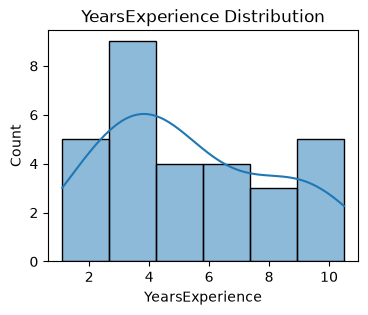

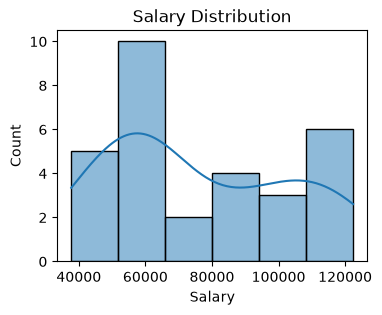

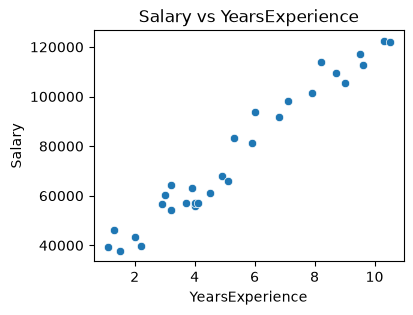

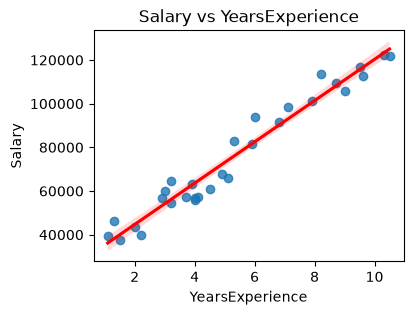

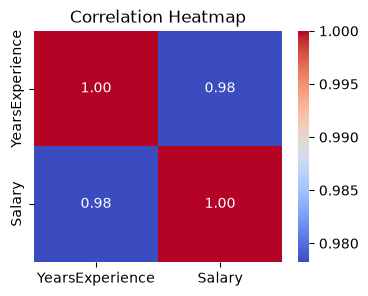

In [13]:
plt.figure(figsize=(4, 3))
sns.histplot(df["YearsExperience"], kde=True)
plt.title("YearsExperience Distribution")
plt.show()

plt.figure(figsize=(4, 3))
sns.histplot(df["Salary"], kde= True)
plt.title("Salary Distribution")
plt.show()

plt.figure(figsize=(4, 3))
sns.scatterplot(x= df["YearsExperience"], y= df["Salary"])
plt.title("Salary vs YearsExperience")
plt.show()

plt.figure(figsize=(4, 3))
sns.regplot(x= df["YearsExperience"], y= df["Salary"], line_kws={'color':'red'})
plt.title("Salary vs YearsExperience")
plt.show()


corr = df.corr()
plt.figure(figsize=(4,3))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()


## 5. Feature and target selection
fitted to all available records for the final prediction equation.

In [15]:
X = df[['YearsExperience']]
y = df['Salary']

model = LinearRegression()
model.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[9449.96]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['YearsExperience']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.579e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


## 6. Model equation

In [16]:
print("Interception (c):", round(model.intercept_, 2))
print("Slope (m):", round(model.coef_[0], 2))

print('\n')
print(f'The Equation is :\n  y = {round(model.coef_[0], 2)}*X + {round(model.intercept_, 2)}')

Interception (c): 25792.2
Slope (m): 9449.96


The Equation is :
  y = 9449.96*X + 25792.2


## 7. Predict existing dataset values

In [20]:
y_pred = model.predict(X)

comparison = pd.DataFrame({
    'Actual Salary': y,
    'Predicted Salary': y_pred
})
display(comparison)

,Actual Salary,Predicted Salary
0,39343.0,36187.158752
1,46205.0,38077.151217
2,37731.0,39967.143681
3,43525.0,44692.124842
4,39891.0,46582.117306
5,56642.0,53197.090931
6,60150.0,54142.087163
7,54445.0,56032.079627
8,64445.0,56032.079627
9,57189.0,60757.060788


## 8. Model evaluation

In [22]:
mae = mean_absolute_error(y, y_pred)
mse = mean_squared_error(y, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y, y_pred)

print("Model Evaluation")

print("MAE(mean absolute error):", mae)

print("MSE(mean squared error):", mse)

print("RMSE(mean sqr root error):", rmse)

print("R2 Score:", r2)


Model Evaluation
MAE(mean absolute error): 4644.2012894435375
MSE(mean squared error): 31270951.722280968
RMSE(mean sqr root error): 5592.043608760662
R2 Score: 0.9569566641435086


## 9. Predict three new values and export CSV

In [27]:
new_values = pd.DataFrame({'YearsExperience': [2.5, 5.0, 10.0]})

predictions = model.predict(new_values)

output = pd.DataFrame({
    'YearsExperience': new_values['YearsExperience'],
    'Predicted Salary': predictions
})

display(output)

output.to_csv("Dataset\Salary_Hike_Predictions.csv", index=False)
print("Prediction CSV saved.")

,YearsExperience,Predicted Salary
0,2.5,49417.106002
1,5.0,73042.011806
2,10.0,120291.823413


Prediction CSV saved.
